# IPL Data Analysis Using Python
**B.Tech 1st Year - Data Analyst Project**

> **Important:** the data used here is **SAMPLE data** (every row is tagged `Data_Type = SAMPLE`). Player names are placeholders (`Player 001` ...). Results describe this sample only - they are **not real IPL statistics**.

**Business problem:** A cricket analytics team wants to understand what influences match results, team performance and player output in a T20 league.

**Questions answered**
1. How are scores and match results distributed?
2. Does winning the toss help? Do teams prefer to bat or field?
3. Which teams and venues perform best?
4. How do team season stats (wins, NRR, runs) relate to each other?
5. Which players are top run-scorers / wicket-takers in the sample?

## Step 1 - Load and inspect the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs('images', exist_ok=True)
import seaborn as sns
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 140)

path = 'IPL_Sample_Data_Raw.xlsx'
matches = pd.read_excel(path, sheet_name='Matches')
teams   = pd.read_excel(path, sheet_name='Team_Stats')
players = pd.read_excel(path, sheet_name='Player_Stats')
for name, d in [('Matches', matches), ('Team_Stats', teams), ('Player_Stats', players)]:
    print(name, d.shape)
matches.head()

Matches (105, 13)
Team_Stats (103, 9)
Player_Stats (103, 11)


,Match_ID,Season,Date,Team_1,Team_2,Venue_City,Toss_Winner,Toss_Decision,Team_1_Score,Team_2_Score,Winner,Run_Difference,Data_Type
0,1,2018,2018-04-22,Chennai Super Kings,Delhi Capitals,Chennai,Chennai Super Kings,bat,148,137.0,Chennai Super Kings,11.0,SAMPLE
1,2,2026,2026-03-25,Rajasthan Royals,Chennai Super Kings,Jaipur,Rajasthan Royals,bat,131,147.0,Chennai Super Kings,16.0,SAMPLE
2,3,2025,2025-05-14,Kolkata Knight Riders,Gujarat Titans,Kolkata,Gujarat Titans,bat,148,177.0,Gujarat Titans,29.0,SAMPLE
3,4,2019,2019-04-26,Rajasthan Royals,Punjab Kings,Jaipur,Punjab Kings,bat,139,147.0,Punjab Kings,8.0,SAMPLE
4,5,2018,2018-05-06,Rajasthan Royals,Mumbai Indians,Jaipur,Mumbai Indians,bat,228,164.0,Rajasthan Royals,64.0,SAMPLE


In [2]:
matches.info()
print(teams.columns.tolist())
print(players.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Match_ID        105 non-null    int64         
 1   Season          105 non-null    int64         
 2   Date            105 non-null    datetime64[us]
 3   Team_1          105 non-null    str           
 4   Team_2          105 non-null    str           
 5   Venue_City      105 non-null    str           
 6   Toss_Winner     105 non-null    str           
 7   Toss_Decision   105 non-null    str           
 8   Team_1_Score    105 non-null    int64         
 9   Team_2_Score    102 non-null    float64       
 10  Winner          101 non-null    str           
 11  Run_Difference  101 non-null    float64       
 12  Data_Type       105 non-null    str           
dtypes: datetime64[us](1), float64(2), int64(3), str(7)
memory usage: 10.8 KB
['Season', 'Team', 'Matches', 'Wins', 'Losses', 

## Step 2 - Clean the data
The raw file is **intentionally messy** (made by `scripts/generate_raw_data.py`) so you can practise cleaning. First we find the problems, then fix them one by one.

In [3]:
for name, d in [('Matches', matches), ('Team_Stats', teams), ('Player_Stats', players)]:
    print(f'{name}: rows = {len(d)}, duplicate rows = {d.duplicated().sum()}')
    print('  missing:', d.isna().sum()[d.isna().sum() > 0].to_dict())
print()
print(matches.Toss_Decision.value_counts().to_dict())   # inconsistent text
print(sorted(matches.Venue_City.unique()))
print('Impossible scores (> 300):', (matches.Team_1_Score > 300).sum(), '| impossible runs (> 1000):', (players.Runs > 1000).sum())

Matches: rows = 105, duplicate rows = 5
  missing: {'Team_2_Score': 3, 'Winner': 4, 'Run_Difference': 4}
Team_Stats: rows = 103, duplicate rows = 3
  missing: {'Wins': 4, 'Losses': 3, 'Points': 5}
Player_Stats: rows = 103, duplicate rows = 3
  missing: {'Runs': 3, 'Average': 5}

{'bat': 52, 'field': 44, 'BAT': 3, ' field': 3, 'Bat ': 1, 'Field ': 1, 'FIELD': 1}
[' Chennai ', ' Hyderabad ', ' Jaipur ', ' Mumbai ', 'Ahmedabad', 'Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Lucknow', 'Mohali', 'Mumbai', 'bengaluru', 'jaipur', 'kolkata', 'mohali']
Impossible scores (> 300): 2 | impossible runs (> 1000): 2


### 2.1 Remove duplicate rows and standardise text

In [4]:
matches = matches.drop_duplicates().reset_index(drop=True)
teams = teams.drop_duplicates().reset_index(drop=True)
players = players.drop_duplicates().reset_index(drop=True)

matches['Toss_Decision'] = matches.Toss_Decision.str.strip().str.lower()
matches['Venue_City'] = matches.Venue_City.str.strip().str.title()
teams['Team'] = teams.Team.str.strip().str.title()
players['Team'] = players.Team.str.strip().str.title()
print(len(matches), len(teams), len(players), 'rows after removing duplicates')
print(matches.Toss_Decision.value_counts().to_dict())
print(sorted(matches.Venue_City.unique()))
print(sorted(teams.Team.unique()))

100 100 100 rows after removing duplicates
{'bat': 54, 'field': 46}
['Ahmedabad', 'Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Lucknow', 'Mohali', 'Mumbai']
['Chennai Super Kings', 'Delhi Capitals', 'Gujarat Titans', 'Kolkata Knight Riders', 'Lucknow Super Giants', 'Mumbai Indians', 'Punjab Kings', 'Rajasthan Royals', 'Royal Challengers Bengaluru', 'Sunrisers Hyderabad']


### 2.2 Fix impossible values and fill missing values
Instead of guessing with the mean, we **recalculate** each value from other columns:
- `Run_Difference` = gap between the two scores; `Winner` = team with the higher score
- a missing/impossible score = the other score +/- the margin (depending on who won)
- `Wins` = Matches - Losses (and the reverse); `Points` = 2 x Wins
- `Average` = Runs / Innings; `Runs` = Average x Innings

In [5]:
# --- Matches ---
matches.loc[matches.Team_1_Score > 300, 'Team_1_Score'] = np.nan        # impossible -> missing
t1_won = matches.Winner == matches.Team_1
t2_won = matches.Winner == matches.Team_2
# scores from the other score and the margin
m1 = matches.Team_1_Score.isna() & matches.Team_2_Score.notna() & matches.Run_Difference.notna()
matches.loc[m1 & t1_won, 'Team_1_Score'] = matches.Team_2_Score + matches.Run_Difference
matches.loc[m1 & t2_won, 'Team_1_Score'] = matches.Team_2_Score - matches.Run_Difference
m2 = matches.Team_2_Score.isna() & matches.Team_1_Score.notna() & matches.Run_Difference.notna()
matches.loc[m2 & t1_won, 'Team_2_Score'] = matches.Team_1_Score - matches.Run_Difference
matches.loc[m2 & t2_won, 'Team_2_Score'] = matches.Team_1_Score + matches.Run_Difference
# margin and winner from the two scores
matches['Run_Difference'] = (matches.Team_1_Score - matches.Team_2_Score).abs()
matches['Winner'] = np.where(matches.Team_1_Score > matches.Team_2_Score, matches.Team_1, matches.Team_2)
for c in ['Team_1_Score', 'Team_2_Score', 'Run_Difference']:
    matches[c] = matches[c].astype(int)

# --- Team_Stats ---
teams['Wins'] = teams.Wins.fillna(teams.Matches - teams.Losses)
teams['Losses'] = teams.Losses.fillna(teams.Matches - teams.Wins)
teams['Points'] = teams.Points.fillna(2 * teams.Wins)
for c in ['Wins', 'Losses', 'Points']:
    teams[c] = teams[c].astype(int)

# --- Player_Stats ---
players.loc[players.Runs > 1000, 'Runs'] = np.nan                       # impossible -> missing
players['Average'] = players.Average.fillna((players.Runs / players.Innings).round(2))
players['Runs'] = players.Runs.fillna((players.Average * players.Innings).round())
players['Runs'] = players.Runs.astype(int)

for name, d in [('Matches', matches), ('Team_Stats', teams), ('Player_Stats', players)]:
    print(f'{name}: rows = {len(d)}, missing = {d.isna().sum().sum()}, duplicates = {d.duplicated().sum()}')

Matches: rows = 100, missing = 0, duplicates = 0
Team_Stats: rows = 100, missing = 0, duplicates = 0
Player_Stats: rows = 100, missing = 0, duplicates = 0


### 2.3 Validate the cleaned data
Logical checks - each should print 0.

In [6]:
print('Team_1 == Team_2 :', (matches.Team_1 == matches.Team_2).sum())
print('Winner not a playing team :', (~((matches.Winner == matches.Team_1) | (matches.Winner == matches.Team_2))).sum())
print('Run_Difference mismatch   :', ((matches.Team_1_Score - matches.Team_2_Score).abs() != matches.Run_Difference).sum())
print('Date year != Season       :', (matches.Date.dt.year != matches.Season).sum())
print('Wins + Losses != Matches  :', (teams.Wins + teams.Losses != teams.Matches).sum())
print('Innings > Matches (players):', (players.Innings > players.Matches).sum())
print('Data_Type values:', matches.Data_Type.unique())

# Extra check: compare with the tidy reference file the raw data was made from
ref = pd.read_excel('IPL_Sample_Data_Template.xlsx', sheet_name=None)
for name, d in [('Matches', matches), ('Team_Stats', teams), ('Player_Stats', players)]:
    same = d.reset_index(drop=True).astype(ref[name].dtypes.to_dict()).equals(ref[name])
    print(f'{name} identical to reference after cleaning:', same)

Team_1 == Team_2 : 0
Winner not a playing team : 0
Run_Difference mismatch   : 0
Date year != Season       : 0
Wins + Losses != Matches  : 0
Innings > Matches (players): 0
Data_Type values: <StringArray>
['SAMPLE']
Length: 1, dtype: str
Matches identical to reference after cleaning: True
Team_Stats identical to reference after cleaning: True
Player_Stats identical to reference after cleaning: True


## Step 3 - Create new columns
`Toss_Winner_Won_Match`, `Winning_Margin_Band`, `Total_Runs_In_Match`, `Batting_First_Team`, `Batting_First_Won`, `Win_Pct`, `Player_Role`.

In [7]:
# Matches
matches['Toss_Winner_Won_Match'] = matches.Toss_Winner == matches.Winner
matches['Total_Runs_In_Match'] = matches.Team_1_Score + matches.Team_2_Score
matches['Margin_Band'] = pd.cut(matches.Run_Difference, bins=[0, 10, 30, 60, 200],
                                labels=['Close (1-10)', 'Moderate (11-30)', 'Comfortable (31-60)', 'Dominant (60+)'])
# Assumption: Team_1 is the team that batted first (the template does not state this explicitly)
matches['Batting_First_Won'] = matches.Winner == matches.Team_1

# Teams
teams['Win_Pct'] = (teams.Wins / teams.Matches * 100).round(1)
teams['Runs_Per_Match'] = (teams.Total_Runs / teams.Matches).round(1)

# Players
players['Player_Role'] = np.select(
    [(players.Runs >= 400) & (players.Wickets >= 15),
     players.Runs >= 400,
     players.Wickets >= 15],
    ['All-rounder', 'Batter', 'Bowler'], default='Squad player')
matches[['Match_ID','Team_1','Team_2','Winner','Run_Difference','Margin_Band','Toss_Winner_Won_Match']].head()

,Match_ID,Team_1,Team_2,Winner,Run_Difference,Margin_Band,Toss_Winner_Won_Match
0,1,Chennai Super Kings,Delhi Capitals,Chennai Super Kings,11,Moderate (11-30),True
1,2,Rajasthan Royals,Chennai Super Kings,Chennai Super Kings,16,Moderate (11-30),False
2,3,Kolkata Knight Riders,Gujarat Titans,Gujarat Titans,29,Moderate (11-30),True
3,4,Rajasthan Royals,Punjab Kings,Punjab Kings,8,Close (1-10),True
4,5,Rajasthan Royals,Mumbai Indians,Rajasthan Royals,64,Dominant (60+),False


In [8]:
import os
os.makedirs('processed', exist_ok=True)
with pd.ExcelWriter('processed/ipl_clean.xlsx') as w:
    matches.to_excel(w, sheet_name='Matches', index=False)
    teams.to_excel(w, sheet_name='Team_Stats', index=False)
    players.to_excel(w, sheet_name='Player_Stats', index=False)
matches.to_csv('processed/matches_clean.csv', index=False)
teams.to_csv('processed/team_stats_clean.csv', index=False)
players.to_csv('processed/player_stats_clean.csv', index=False)
print('Saved cleaned files to data/processed/')

Saved cleaned files to data/processed/


## Step 4 - Exploratory analysis
Four saved charts (like the student project): overall performance, toss and teams, correlation, group comparison.
### 4.1 Overall picture: scores and margins

       Team_1_Score  Team_2_Score  Run_Difference  Total_Runs_In_Match
count         100.0         100.0           100.0                100.0
mean          180.3         172.7            37.3                353.0
std            32.9          30.3            24.1                 45.5
min           120.0         123.0             1.0                257.0
25%           151.8         147.0            17.0                322.8
50%           180.0         173.0            30.5                354.0
75%           210.2         196.0            59.0                388.2
max           230.0         230.0            97.0                451.0


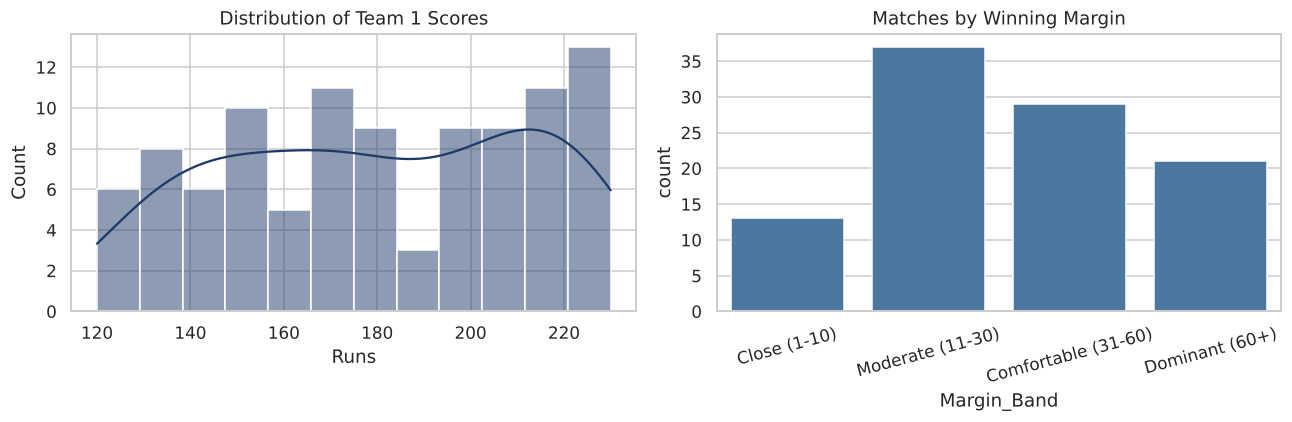

In [9]:
print(matches[['Team_1_Score','Team_2_Score','Run_Difference','Total_Runs_In_Match']].describe().round(1))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(matches.Team_1_Score, bins=12, kde=True, color='#1f3a68', ax=ax[0])
ax[0].set_title('Distribution of Team 1 Scores'); ax[0].set_xlabel('Runs')
order = ['Close (1-10)', 'Moderate (11-30)', 'Comfortable (31-60)', 'Dominant (60+)']
sns.countplot(x='Margin_Band', data=matches, order=order, color='#3f77ab', ax=ax[1])
ax[1].set_title('Matches by Winning Margin'); ax[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.savefig('images/01_overall_performance.png', dpi=150); plt.show()

### 4.2 Toss and team results

Toss winner won the match in 45.0% of matches
{'bat': 54, 'field': 46}
{'bat': 48.1, 'field': 41.3}
                             Played  Won  Win_Pct
Chennai Super Kings              18   13     72.2
Royal Challengers Bengaluru      19   11     57.9
Kolkata Knight Riders            28   16     57.1
Delhi Capitals                   26   14     53.8
Sunrisers Hyderabad              17    9     52.9
Gujarat Titans                   19    9     47.4
Lucknow Super Giants             17    7     41.2
Mumbai Indians                   22    9     40.9
Rajasthan Royals                 19    7     36.8
Punjab Kings                     15    5     33.3


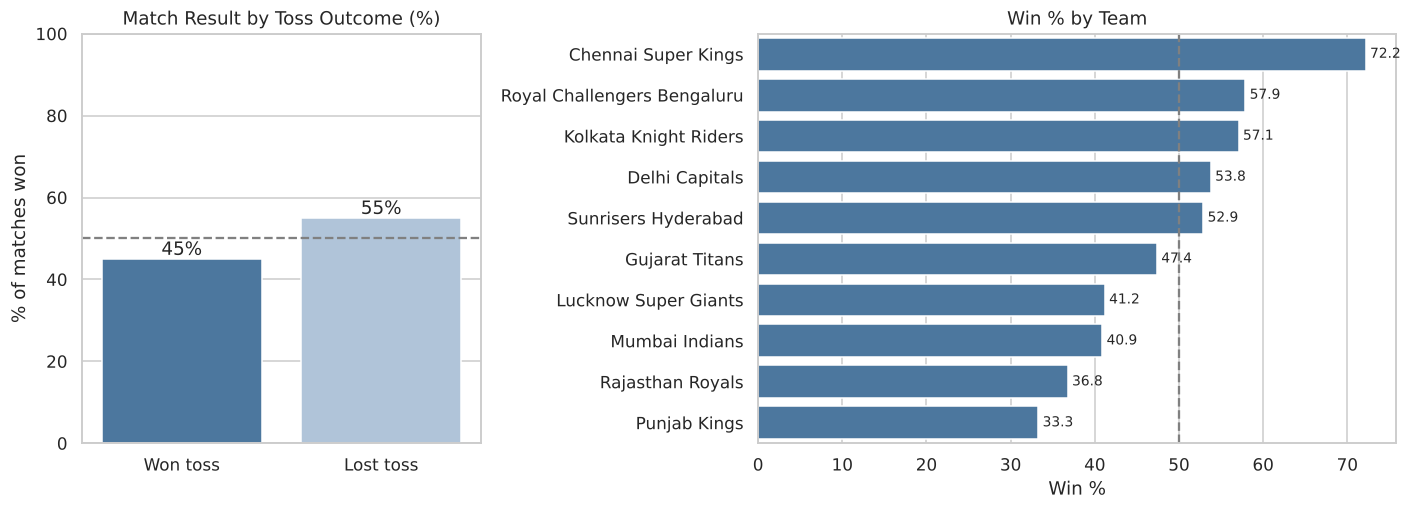

In [10]:
toss_win_pct = matches.Toss_Winner_Won_Match.mean() * 100
print(f'Toss winner won the match in {toss_win_pct:.1f}% of matches')
print(matches.Toss_Decision.value_counts().to_dict())
print(matches.groupby('Toss_Decision').Toss_Winner_Won_Match.mean().mul(100).round(1).to_dict())

played = pd.concat([matches.Team_1, matches.Team_2]).value_counts()
won = matches.Winner.value_counts()
team_tbl = pd.DataFrame({'Played': played, 'Won': won}).fillna(0).astype(int)
team_tbl['Win_Pct'] = (team_tbl.Won / team_tbl.Played * 100).round(1)
team_tbl = team_tbl.sort_values('Win_Pct', ascending=False)
print(team_tbl)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1, 1.6]})
sns.barplot(x=['Won toss', 'Lost toss'], y=[toss_win_pct, 100 - toss_win_pct], hue=['Won toss', 'Lost toss'],
            palette=['#3f77ab', '#a9c4e0'], legend=False, ax=ax[0])
ax[0].axhline(50, ls='--', color='grey'); ax[0].set_ylim(0, 100)
ax[0].set_title('Match Result by Toss Outcome (%)'); ax[0].set_ylabel('% of matches won')
for i, v in enumerate([toss_win_pct, 100 - toss_win_pct]): ax[0].text(i, v + 1, f'{v:.0f}%', ha='center')
sns.barplot(x='Win_Pct', y=team_tbl.index, data=team_tbl, color='#3f77ab', ax=ax[1])
ax[1].axvline(50, ls='--', color='grey'); ax[1].set_title('Win % by Team'); ax[1].set_xlabel('Win %'); ax[1].set_ylabel('')
for i, v in enumerate(team_tbl.Win_Pct): ax[1].text(v + 0.5, i, f'{v}', va='center', fontsize=9)
plt.tight_layout(); plt.savefig('images/02_toss_and_teams.png', dpi=150); plt.show()

### 4.3 Team season stats and correlations
`Points` (= 2 x Wins) and `Win_Pct` are exact copies of `Wins` in information, so only Wins, Net_Run_Rate and Total_Runs are compared.

              Wins  Net_Run_Rate  Total_Runs
Wins          1.00          0.11       -0.20
Net_Run_Rate  0.11          1.00       -0.06
Total_Runs   -0.20         -0.06        1.00


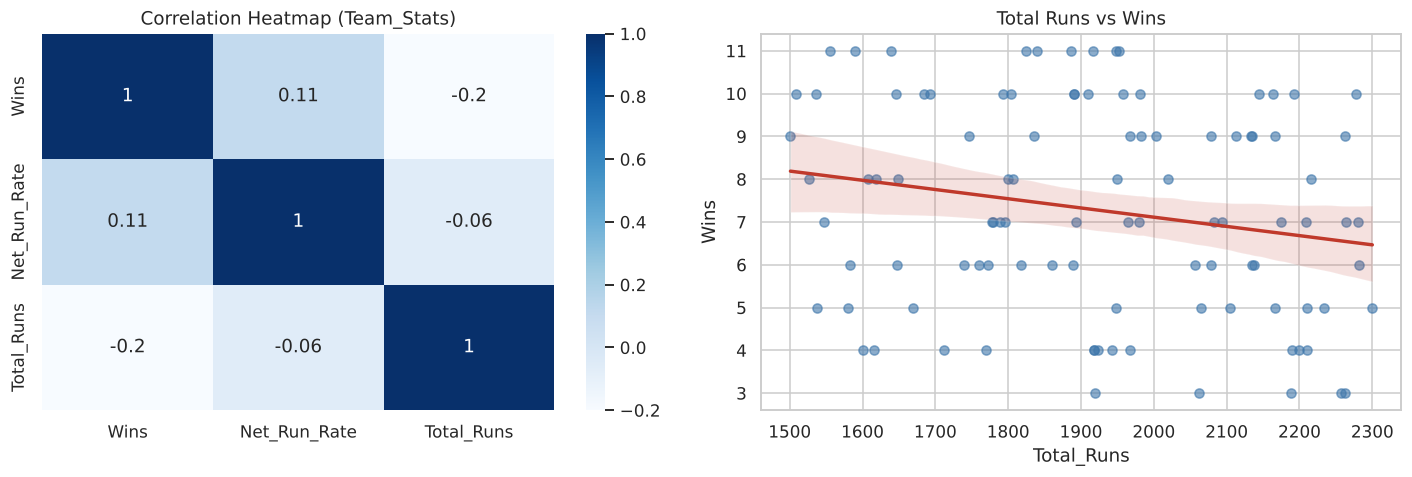

In [11]:
cols = ['Wins', 'Net_Run_Rate', 'Total_Runs']
corr = teams[cols].corr().round(2)
print(corr)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(corr, annot=True, cmap='Blues', ax=ax[0]); ax[0].set_title('Correlation Heatmap (Team_Stats)')
sns.regplot(x='Total_Runs', y='Wins', data=teams, scatter_kws={'alpha': .6, 'color': '#3f77ab'}, line_kws={'color': '#c0392b'}, ax=ax[1])
ax[1].set_title('Total Runs vs Wins')
plt.tight_layout(); plt.savefig('images/03_correlation.png', dpi=150); plt.show()

### 4.4 Group comparison: venues, seasons and players

            Matches  Avg_Total_Runs
Venue_City                         
Hyderabad         8           378.4
Chennai          10           372.9
Ahmedabad         9           362.9
Mumbai            7           359.7
Lucknow           9           357.7
Bengaluru         8           357.2
Jaipur           11           351.5
Kolkata          17           340.9
Mohali           10           338.5
Delhi            11           330.0

{2017: 184.2, 2018: 175.0, 2019: 175.9, 2020: 172.9, 2021: 184.2, 2022: 180.0, 2023: 174.8, 2024: 175.0, 2025: 164.7, 2026: 175.6}

    Player                        Team  Season  Runs  Average  Strike_Rate
Player 022         Chennai Super Kings    2025   698    77.56       110.47
Player 059                Punjab Kings    2022   686    57.17       110.93
Player 001              Mumbai Indians    2021   683    52.54       186.31
Player 052                Punjab Kings    2026   682    62.00       118.59
Player 095 Royal Challengers Bengaluru    2023   659    59.9

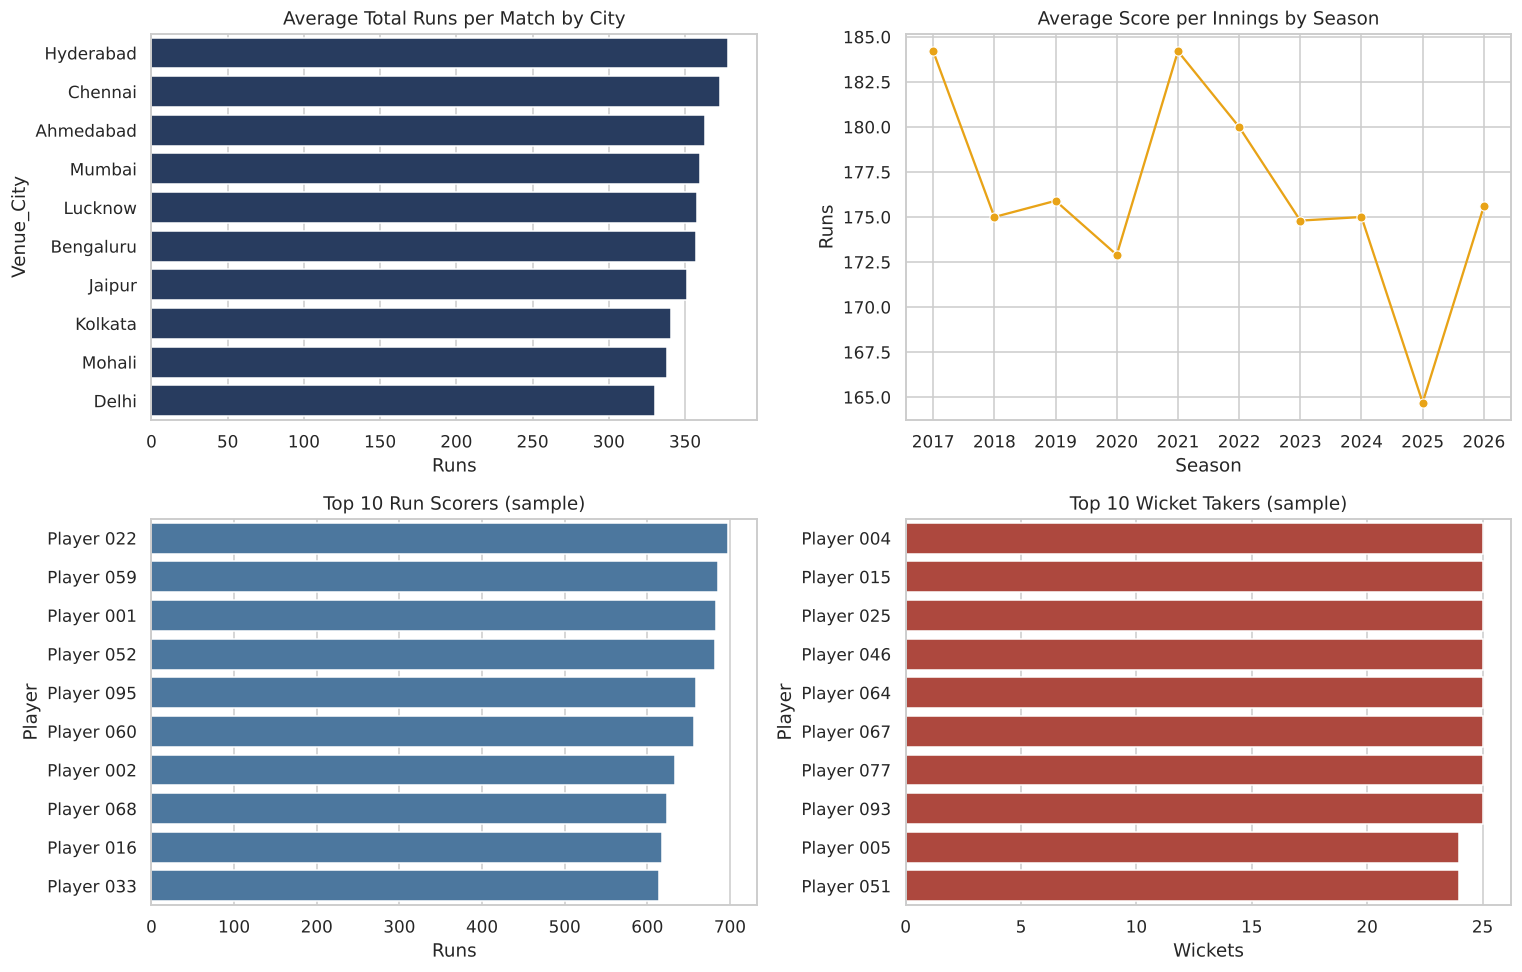

In [12]:
venue = matches.groupby('Venue_City').agg(Matches=('Match_ID', 'count'),
                                       Avg_Total_Runs=('Total_Runs_In_Match', 'mean')).round(1)
venue = venue.sort_values('Avg_Total_Runs', ascending=False)
season = matches.assign(Avg_Score=(matches.Team_1_Score + matches.Team_2_Score) / 2).groupby('Season').Avg_Score.mean().round(1)
top_runs = players.nlargest(10, 'Runs')[['Player', 'Team', 'Season', 'Runs', 'Average', 'Strike_Rate']]
top_wkts = players.nlargest(10, 'Wickets')[['Player', 'Team', 'Season', 'Wickets']]
print(venue); print(); print(season.to_dict()); print()
print(top_runs.to_string(index=False)); print(); print(top_wkts.to_string(index=False))
print(); print(players.Player_Role.value_counts().to_dict())

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
sns.barplot(x=venue.Avg_Total_Runs, y=venue.index, color='#1f3a68', ax=ax[0, 0])
ax[0, 0].set_title('Average Total Runs per Match by City'); ax[0, 0].set_xlabel('Runs')
sns.lineplot(x=season.index, y=season.values, marker='o', color='#e8a317', ax=ax[0, 1])
ax[0, 1].set_title('Average Score per Innings by Season'); ax[0, 1].set_xticks(season.index); ax[0, 1].set_ylabel('Runs')
sns.barplot(x='Runs', y='Player', data=top_runs, color='#3f77ab', ax=ax[1, 0]); ax[1, 0].set_title('Top 10 Run Scorers (sample)')
sns.barplot(x='Wickets', y='Player', data=top_wkts, color='#c0392b', ax=ax[1, 1]); ax[1, 1].set_title('Top 10 Wicket Takers (sample)')
plt.tight_layout(); plt.savefig('images/04_group_comparison.png', dpi=150); plt.show()

## Step 5 - Insights and recommendations
Values below are computed from the code, so they stay correct if the data changes.

In [13]:
best = team_tbl.index[0]; worst = team_tbl.index[-1]
top_city = venue.index[0]; low_city = venue.index[-1]
bat_first = matches.Batting_First_Won.mean() * 100
bat_pref = (matches.Toss_Decision == 'bat').mean() * 100
print(f'1. Average total runs in a match: {matches.Total_Runs_In_Match.mean():.0f}; average winning margin: {matches.Run_Difference.mean():.1f} runs.')
print(f'2. Toss winners won {toss_win_pct:.1f}% of matches. With only 100 matches a gap of this size from 50% can happen by chance, so the sample gives no evidence that the toss helps.')
print(f'3. Teams chose to bat after winning the toss {bat_pref:.0f}% of the time.')
print(f'4. Highest win % in matches: {best} ({team_tbl.Win_Pct.iloc[0]}%); lowest: {worst} ({team_tbl.Win_Pct.iloc[-1]}%). Teams played only {team_tbl.Played.min()}-{team_tbl.Played.max()} sample matches, so treat this ranking as indicative only.')
print(f'5. Highest-scoring city: {top_city} ({venue.Avg_Total_Runs.iloc[0]} runs/match); lowest: {low_city} ({venue.Avg_Total_Runs.iloc[-1]}).')
print(f'6. Correlation of Wins with Total_Runs: {corr.loc["Wins","Total_Runs"]}; with Net_Run_Rate: {corr.loc["Wins","Net_Run_Rate"]}. Both are weak, so in this sample neither runs nor NRR explains wins well.')
print(f'7. Team_1 (assumed batting first) won {bat_first:.0f}% of matches.')
print('\nLimitations: sample data, only 100 rows per sheet, Team_Stats and Matches are independent samples. Do not generalise to real IPL.')

1. Average total runs in a match: 353; average winning margin: 37.3 runs.
2. Toss winners won 45.0% of matches. With only 100 matches a gap of this size from 50% can happen by chance, so the sample gives no evidence that the toss helps.
3. Teams chose to bat after winning the toss 54% of the time.
4. Highest win % in matches: Chennai Super Kings (72.2%); lowest: Punjab Kings (33.3%). Teams played only 15-28 sample matches, so treat this ranking as indicative only.
5. Highest-scoring city: Hyderabad (378.4 runs/match); lowest: Delhi (330.0).
6. Correlation of Wins with Total_Runs: -0.2; with Net_Run_Rate: 0.11. Both are weak, so in this sample neither runs nor NRR explains wins well.
7. Team_1 (assumed batting first) won 60% of matches.

Limitations: sample data, only 100 rows per sheet, Team_Stats and Matches are independent samples. Do not generalise to real IPL.


### Recommendations
- Treat these results as a **method demonstration**; re-run the notebook on real IPL data (same columns) to get real conclusions.
- Do not draw strategy conclusions from the toss or team rankings here: the sample is small and the toss gap is within chance.
- Next steps with real data: test whether the toss effect is statistically significant per venue, and compare chasing vs defending at each ground.
- The weak link between runs/NRR and wins in `Team_Stats` is a property of this random sample; check it again on real season tables.

### Limitations
- Sample data with placeholder players; small size (100 rows per sheet).
- Whether Team_1 batted first is an assumption.
- Correlation does not prove causation.